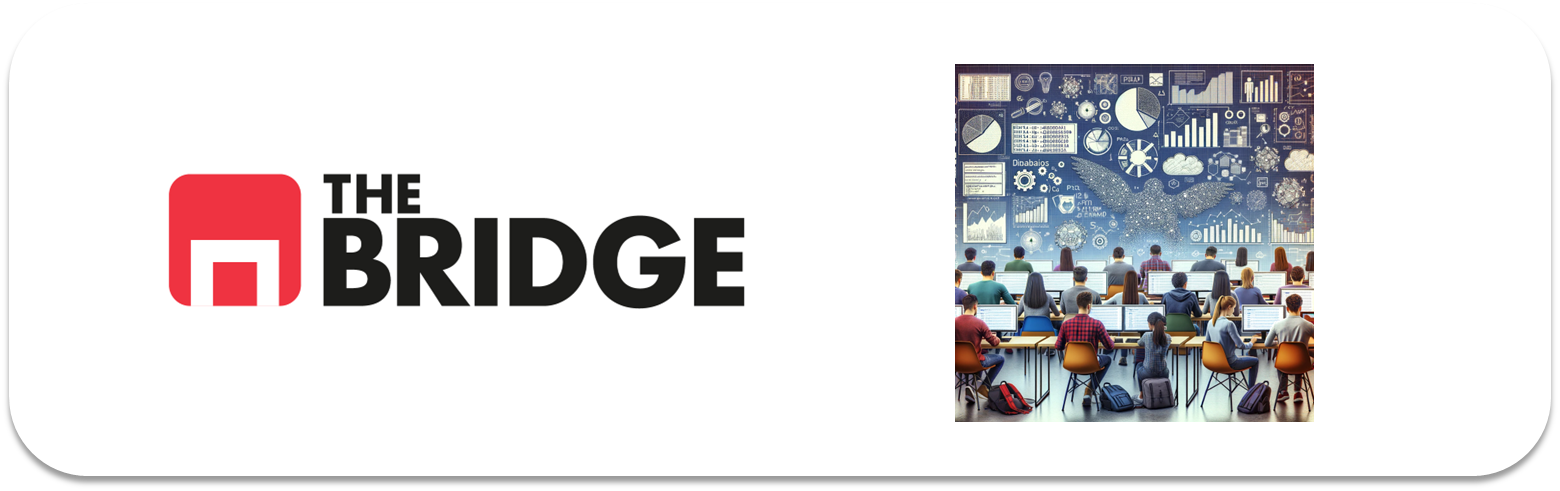

## PRÁCTICA: **Regresión Lineal**

* La práctica consiste en hacer un modelado completo de un problema que ya conoces, la predicción de casas, pero con otro dataset.

### Modelo de Regresión Lineal

El objetivo del modelo que tienes que construir es predecir la mediana del precio de las casas en una zona del área metropolitana de Boston dadas las características de las mismas. Sí, es parecido pero no igual a lo que hemos venido haciendo.

Aquí tienes una descripción de las variables del dataset, del que tendrás que decidir el target:  

***CRIM:*** Tasa de criminalidad per cápita por ciudad  
***ZN:*** Proporción de terreno residencial destinado a lotes de más de 25,000 pies cuadrados  
***INDUS:*** Proporción de acres de negocios no minoristas por ciudad  
***CHAS:*** Variable ficticia del río Charles (= 1 si el sector limita con el río; 0 en caso contrario)  
***NOX:*** Concentración de óxidos de nitrógeno (partes por 10 millones)  
***RM:*** Número promedio de habitaciones por vivienda  
***AGE:*** Proporción de unidades ocupadas por el propietario construidas antes de 1940  
***DIS:*** Distancias ponderadas a cinco centros de empleo de Boston  
***RAD:*** Índice de accesibilidad a autopistas radiales  
***TAX:*** Tasa de impuesto sobre la propiedad de valor total por $10,000  
***PTRATIO:*** Relación alumno-maestro por ciudad  
***LSTAT:*** % de población de estatus socioeconómico bajo  
***MEDV:*** Valor mediano de las viviendas ocupadas por sus propietarios en miles de dólares  

### Indicaciones

A continuación tienes las indicaciones para hacer el modelado. No necesariamente tienes que seguirlas al pie de la letra, porque a partir de ahora ya las prácticas obligatorias dejarán de ser mayormente guiadas por ejercicios y serán más de libre desarrollo, aunque con objetivos específicos, claros y determinados. 

En concreto se pide hacer un modelo de regresión lineal, evaluarlo contra un dataset de test reservado del original mostrando MAE, RMSE, MSE y $R^2$ y comparar las predicciones con los valores reales.

Los pasos para guiar el trabajo:
1. Carga el dataset. Está limpio y no necesitarás completar nulos, ni repasar los valores de las columnas.
2. Escoge y analiza la variable target de forma gráfica para ver la idoneidad de hacer un modelo de regresión.
3. Haz el split en train y test que creas conveniente y de la forma que creas conveniente.
4. Construye las parejas X,y de train y test
5. Haz un mini-EDA, selecciona las features que quieres quedarte y por qué.
6. Trata las variables para que funcionen lo mejor posible en el modelo.
7. Construye un modelo de regresión lineal.
8. Analiza si lo crees conveniente los pesos y la importancia de las features.
9. Evalúa tu modelo. Haz una pequeña evaluación de su capacidad de generalización. Compara gráficamente las predicciones con los valores reales.
10. Expresa tus conclusiones: ¿es un buen modelo? ¿qué features son las más importantes? ¿cómo crees que podrías mejorarlo?



In [1]:
import pandas as pd 
import numpy as np 
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as snn
plt.style.use('seaborn-v0_8')
from scipy import stats


In [2]:
boston=pd.read_csv("data/boston_fixed.csv", sep="|")
boston.head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2
5,0.02985,0.0,2.18,0.0,0.458,6.430,58.7,6.0622,3.0,222.0,18.7,5.21,28.7
6,0.08829,12.5,7.87,0.0,0.524,6.012,66.6,5.5605,5.0,311.0,15.2,12.43,22.9
7,0.14455,12.5,7.87,0.0,0.524,6.172,96.1,5.9505,5.0,311.0,15.2,19.15,27.1
8,0.21124,12.5,7.87,0.0,0.524,5.631,100.0,6.0821,5.0,311.0,15.2,29.93,16.5
9,0.17004,12.5,7.87,0.0,0.524,6.004,85.9,6.5921,5.0,311.0,15.2,17.10,18.9


In [3]:
# DIVIDO 
# features
X=boston[["CRIM", "ZN", "INDUS", "CHAS", "NOX","RM","AGE","DIS", "RAD", "TAX", "PTRATIO", "LSTAT"]]
# target
y=boston["MEDV"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X , y, test_size=0.2, random_state=42)

print(X.shape)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape) # devuelve las y como serie pandas como debe ser
print(y_test.shape)

(506, 12)
(404, 12)
(102, 12)
(404,)
(102,)


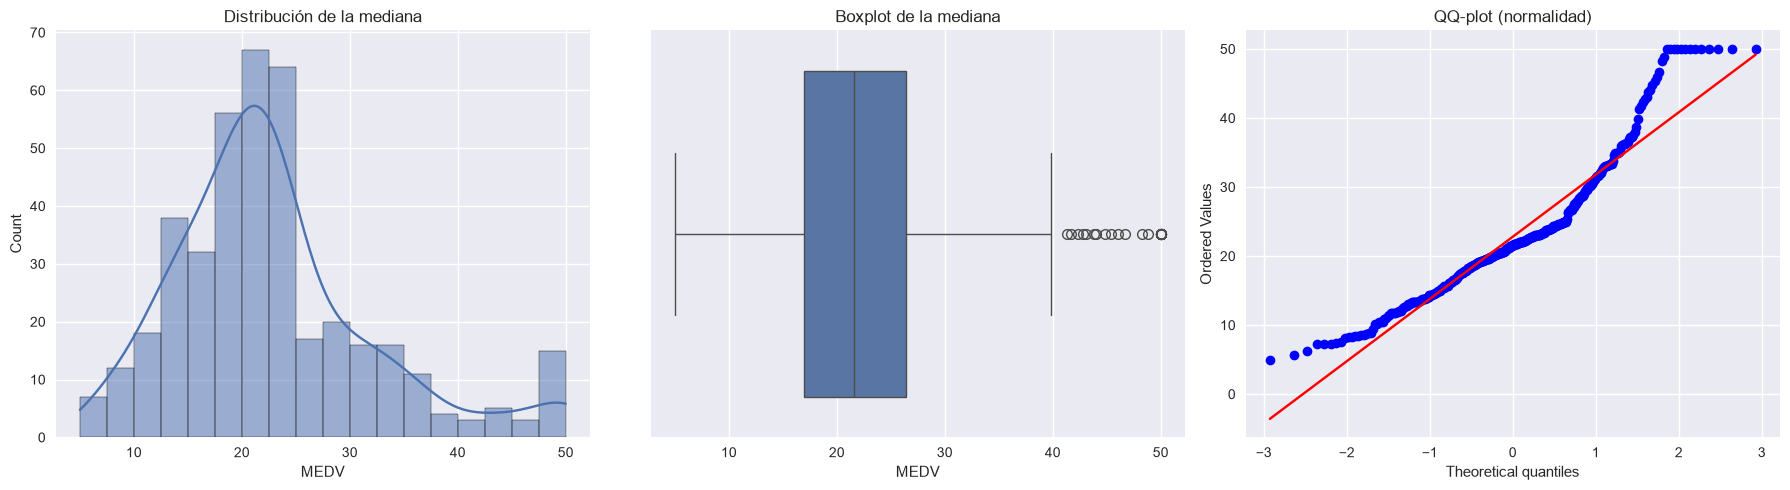

count    404.000000
mean      22.796535
std        9.332147
min        5.000000
25%       16.950000
50%       21.600000
75%       26.400000
max       50.000000
Name: MEDV, dtype: float64
Asimetría (skew): 1.05
Curtosis: 1.24


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histograma + KDE: forma de la distribución
snn.histplot(y_train, kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de la mediana")

# 2. Boxplot: outliers y dispersión
snn.boxplot(x=y_train, ax=axes[1])
axes[1].set_title(f"Boxplot de la mediana")

# 3. QQ-plot: comparación con una distribución normal
# QQ-plot: si los puntos siguen la línea diagonal, la distribución es cercana a la normal. Si se curvan en los extremos, hay asimetría o colas pesadas.
# Skew: valores entre -0.5 y 0.5 indican distribución prácticamente simétrica; por encima de 1 (o por debajo de -1) hay asimetría fuerte.
stats.probplot(y_train, dist="norm", plot=axes[2])
axes[2].set_title("QQ-plot (normalidad)")

plt.tight_layout()
plt.show()

# Resumen numérico
print(y_train.describe())
print(f"Asimetría (skew): {y_train.skew():.2f}")
print(f"Curtosis: {y_train.kurtosis():.2f}")

La regresion lineal asume que los errores siguen una distribucion normal.
Cuando hay mucha asimetría de los valores, seguramente los errores tmbn la tengan.
Entonces puedo probar con aplicar el log a ver si se aproxima mejor.
También puede pasar que sea un problema categórico de 2 posibles valores, donde convenga más aplicar un modelo de clasificación.

En este caso el log no mejora nada y es un problema numérico con lo que nos quedamos con regresión. 

Próximos pasos: 
5. Haz un mini-EDA, selecciona las features que quieres quedarte y por qué.
6. Trata las variables para que funcionen lo mejor posible en el modelo.
7. Construye un modelo de regresión lineal.

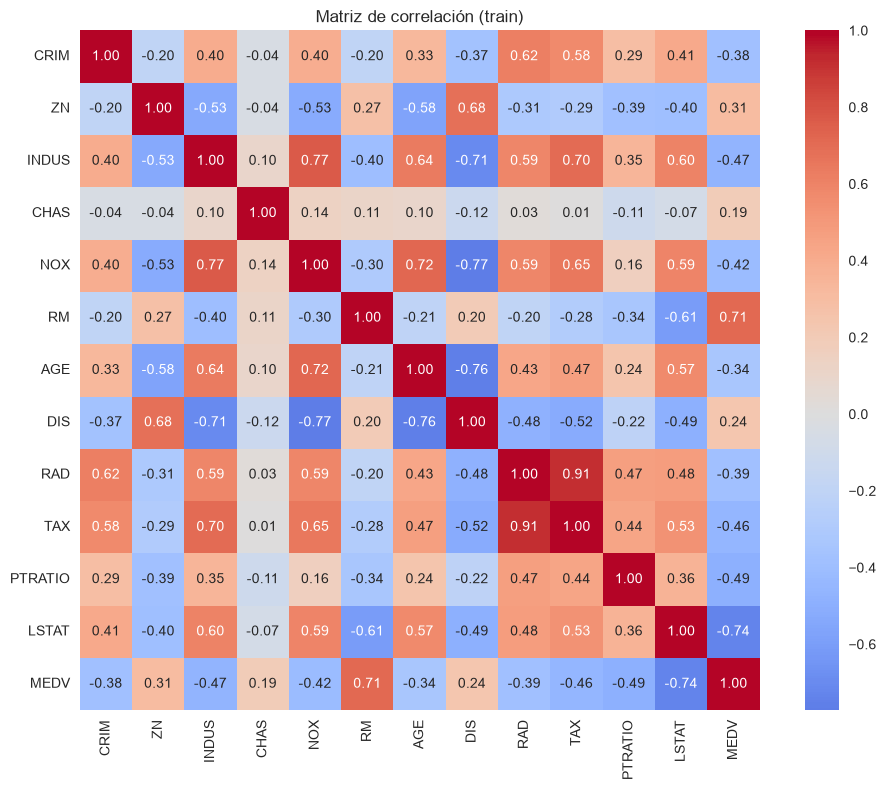

In [6]:
# Unir features y target en un solo DataFrame
train = pd.concat([X_train, y_train], axis=1)
corr_matrix=train.corr(numeric_only=True)
plt.figure(figsize=(10,8))
snn.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriz de correlación (train)")
plt.tight_layout()
plt.show()

Correlaciones positivas fuertes: RM (0.71), ZN (0.31), DIS(0.24)

Correlaciones negativas fuertes: CRIM(-0.38), INDUS(-0.47), NOX(-0.42), AGE(-0.34), RAD(-0.39), TAX(-0.46), PTRATIO(-0.49), LSTAT(-0.74)

Despreciadas: CHAS porque es binaria

In [7]:
X_train.describe()


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT
count,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000
mean,3.609125,11.569307,10.985050,0.071782,0.556484,6.315891,68.556436,3.808195,9.356436,404.032178,18.318317,12.457351
std,8.875058,23.152481,6.894618,0.258447,0.117704,0.709452,27.994922,2.131226,8.589721,166.172655,2.228701,7.110381
min,0.009060,0.000000,0.740000,0.000000,0.385000,3.863000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000
25%,0.081437,0.000000,5.130000,0.000000,0.452000,5.890500,45.550000,2.087875,4.000000,279.000000,16.800000,6.772500
50%,0.261390,0.000000,8.560000,0.000000,0.538000,6.210000,77.700000,3.175750,5.000000,330.000000,18.700000,10.925000
75%,3.202962,20.000000,18.100000,0.000000,0.631000,6.636750,93.650000,5.400800,12.000000,666.000000,20.200000,16.372500
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000


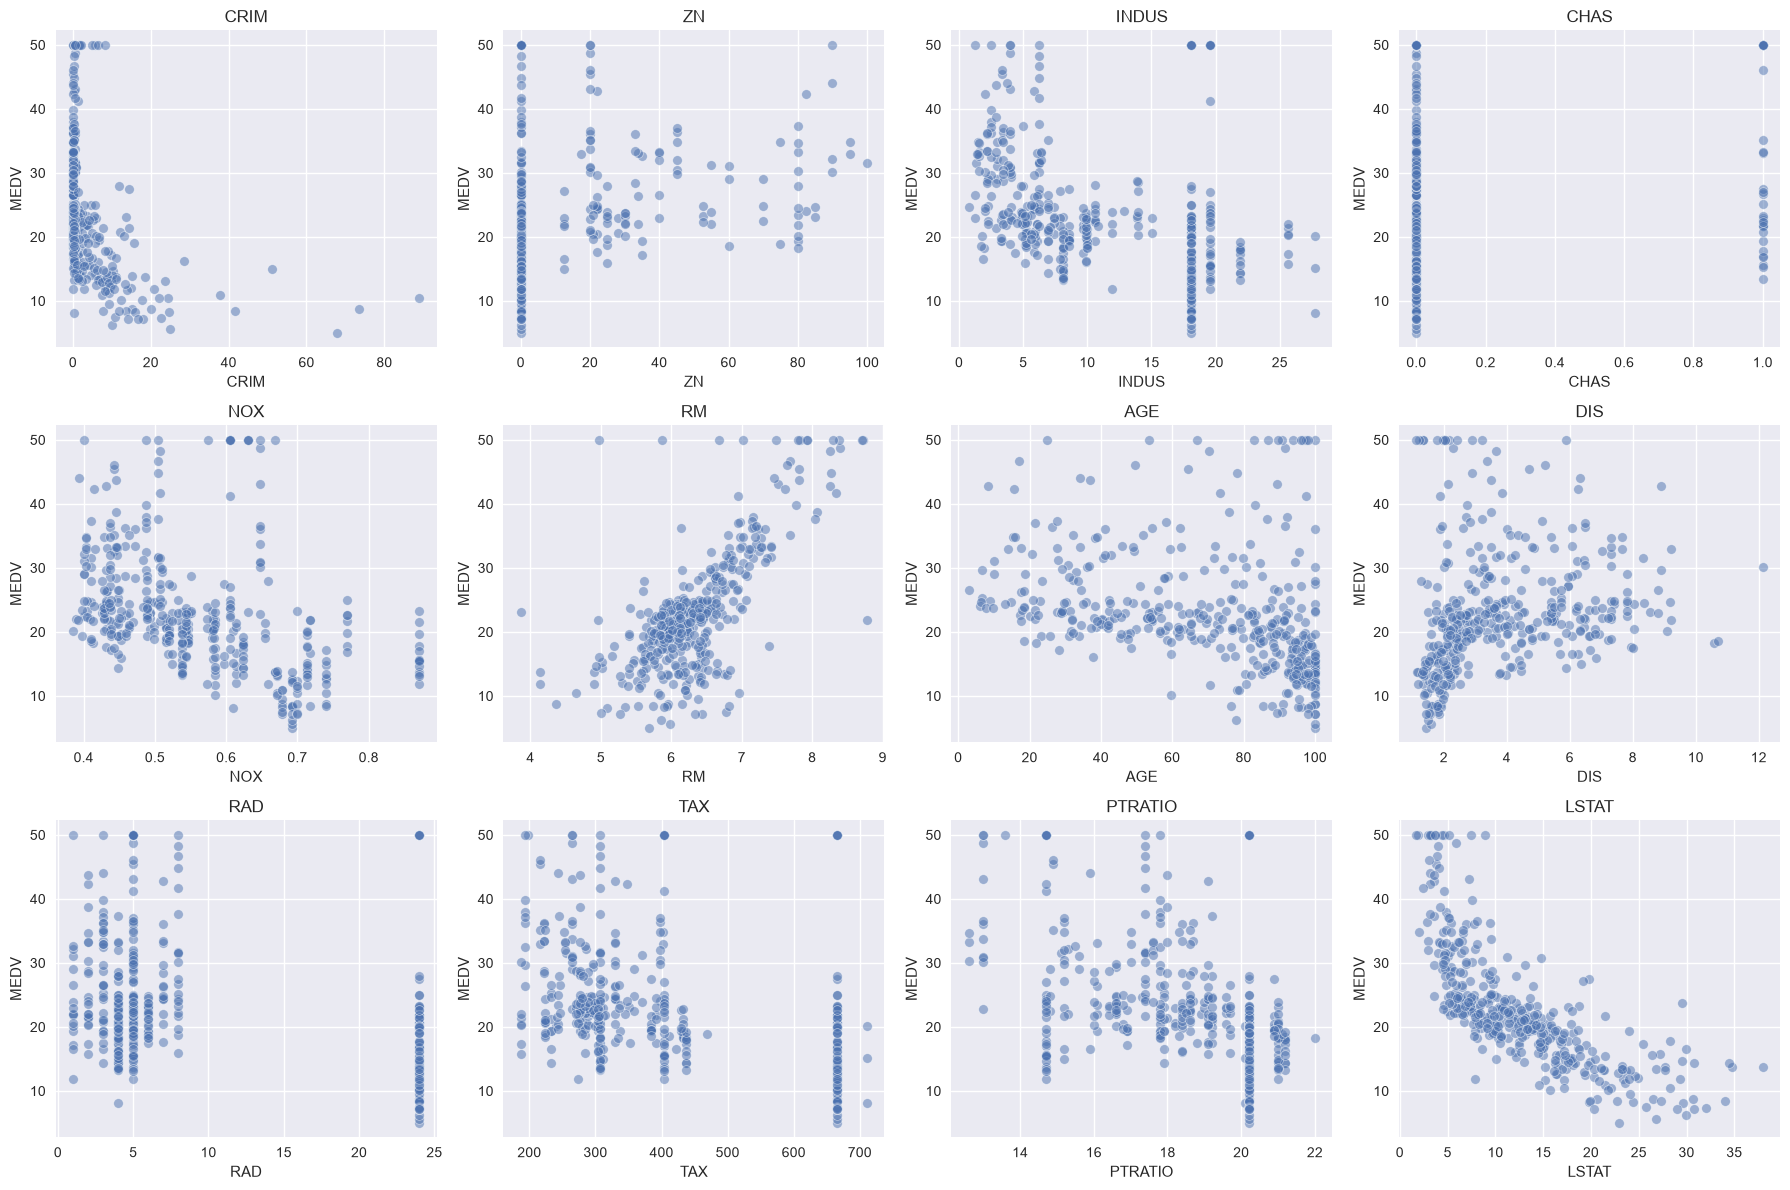

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for ax, col in zip(axes, X_train.columns):
    snn.scatterplot(x=train[col], y=train[y_train.name], ax=ax, alpha=0.5)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [9]:
# Borramos las cols que no usaremos
X_train.drop(columns='CHAS',inplace=True)
X_test.drop(columns='CHAS',inplace=True)

# Estandarizamos los datos antes de aplicar el regresor 
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
# Si hicieras fit con el test (o con train+test), la media y la desviación del scaler incluirían información del test, y eso se llama fuga de datos
X_test_scaled = scaler.transform(X_test)

In [10]:
from sklearn.linear_model import LinearRegression
# Creamos un objeto
lm = LinearRegression()
# Entrenamos con los datos de train
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[-0.13, 0.03, 0.05,...,-0.01,-0.93,-0.56]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['CRIM','ZN','INDUS',...,'TAX','PTRATIO','LSTAT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,37.15
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)


In [11]:
# Interpretacion de los coefs
coef_df = pd.DataFrame(lm.coef_, X_train.columns, 
                      columns=['Coefficient'])
abs(coef_df).sort_values("Coefficient")

,Coefficient
AGE,0.002153
TAX,0.012724
ZN,0.032870
INDUS,0.046684
CRIM,0.134668
RAD,0.264320
LSTAT,0.557083
PTRATIO,0.925911
DIS,1.483326
RM,4.295850


Coefs con máxima importancia como esperabamos: RM, DIS, NOX, LSTAT, PRATIO, 
Las que bajan: ZN, TAX, RAD, AGE, INDUS, CRIM

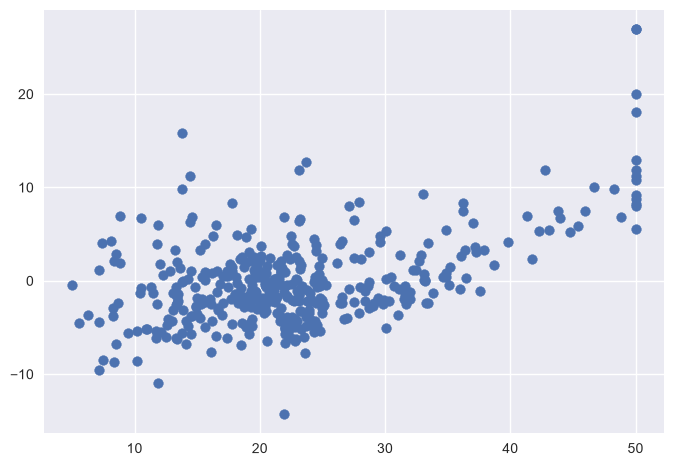

In [ ]:
# # Visualizamos el resultado de la regresión lineal
# def viz_linear():
#     plt.scatter(X_train, y_train, color='red')
#     plt.plot(X_train, lm.predict(X_train), color='blue')
#     plt.title('Regresión lineal')
#     plt.xlabel('')
#     plt.ylabel('características')
#     plt.show()

# viz_linear()

# Posiblemente poninomial???
plt.scatter(y_train, y_train - lm.predict(X_train));

In [15]:
#### Error contra todo el train:
from sklearn.metrics import root_mean_squared_error
rmse_lin = root_mean_squared_error(y_train, lm.predict(X_train)) # Raíz cuadrada del error cuadrático medio (RMSE),
# que está en las mismas unidades que el target
print(rmse_lin)

4.813708611619444


In [14]:
#-----------------CROSS VALIDATION CON TEST---------------------------
from sklearn.model_selection import cross_val_score


lin_rmses = -cross_val_score(lm, X_train, y_train,
                              scoring="neg_root_mean_squared_error", cv=10) # k = 10
pd.Series(lin_rmses).describe()

count    10.000000
mean      4.957500
std       0.858738
min       3.856661
25%       4.346255
50%       4.832075
75%       5.575580
max       6.350617
dtype: float64

Error en train 4.81 vs Error en cv ligeramente mayor: 4.96

Siguentes pasos: 9. Evalúa tu modelo. Haz una pequeña evaluación de su capacidad de generalización. Compara gráficamente las predicciones con los valores reales.
10. Expresa tus conclusiones: ¿es un buen modelo? ¿qué features son las más importantes? ¿cómo crees que podrías mejorarlo?



In [16]:
test_predict = lm.predict(X_test)
rmse_lin_test = root_mean_squared_error(y_test, test_predict)
print(rmse_lin_test)

4.790843475071613


Generaliza bien, pues no se equivoca mas es test, sino un pelin menos. Por lo que no tendría sentido regularizar???

posiblemente mejore eliminando características no tan importantes

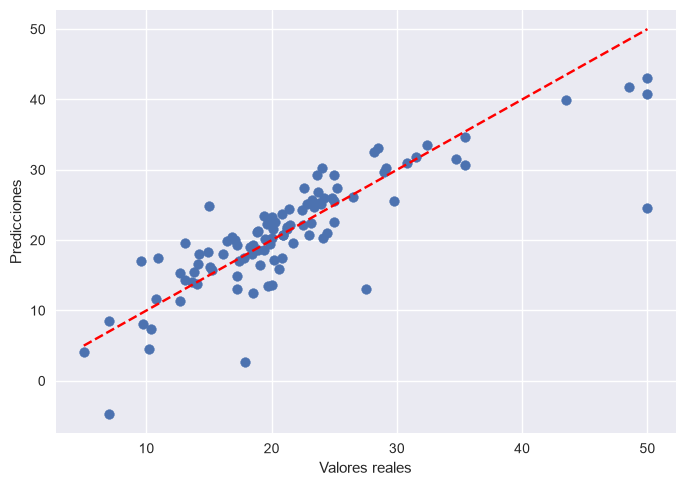

In [17]:
# y_test: valores reales | y_pred: predicciones del modelo
plt.scatter(y_test, test_predict)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")  # línea ideal
plt.xlabel("Valores reales")
plt.ylabel("Predicciones")
plt.show()

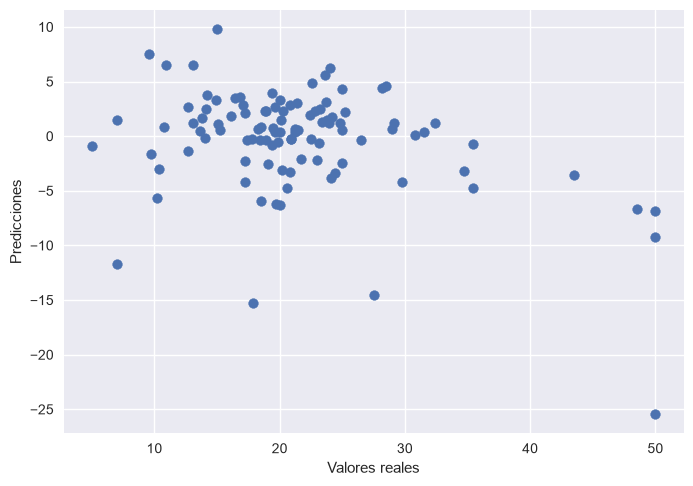

In [18]:
plt.scatter(y_test, test_predict-y_test)
plt.xlabel("Valores reales")
plt.ylabel("Predicciones")
plt.show()